In [1]:
# Import required libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import numpy as np


In [2]:
# Set style for better plots - using only seaborn theme
# Set style for better visualization
sns.set_theme(style="whitegrid", font_scale=1.2)
plt.rcParams['figure.figsize'] = [12, 8]
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 14

# Load dataset
dataset = pd.read_csv('./Version_2_Combined_DataSet.csv')

In [3]:
# removing _extended from names of DC in dataset

dataset['DC'] = dataset['DC'].str.replace('_extended', '')

# Using dataset with only 4 DCS  FUDS, FUDSfast, US06City, US06HW

dataset = dataset[dataset['DC'].isin(['FUDS', 'FUDSfast', 'US06City', 'US06HW'])]


In [4]:
# printing head of dataset

print(dataset.head())

# printing tail of dataset

print(dataset.tail())

      w1    w2    w3       wPL        DC       range
1   0.49  0.45  0.65  0.000019  US06City  170.073440
3   0.15  0.96  0.94  0.000024      FUDS  167.661833
9   0.40  0.13  0.03  0.000018  US06City  169.448903
11  0.51  0.37  0.23  0.000083  US06City  169.961658
13  0.44  0.78  0.15  0.000088      FUDS  167.661833
        w1    w2    w3       wPL        DC       range
2794  0.95  0.10  0.39  0.000018  US06City  170.686667
2795  0.09  0.24  0.90  0.000023  FUDSfast  140.098917
2797  0.27  1.00  0.83  0.000090      FUDS  167.661833
2798  0.35  0.90  0.01  0.000026  US06City  170.073440
2799  0.63  0.53  0.19  0.000066      FUDS  167.661833


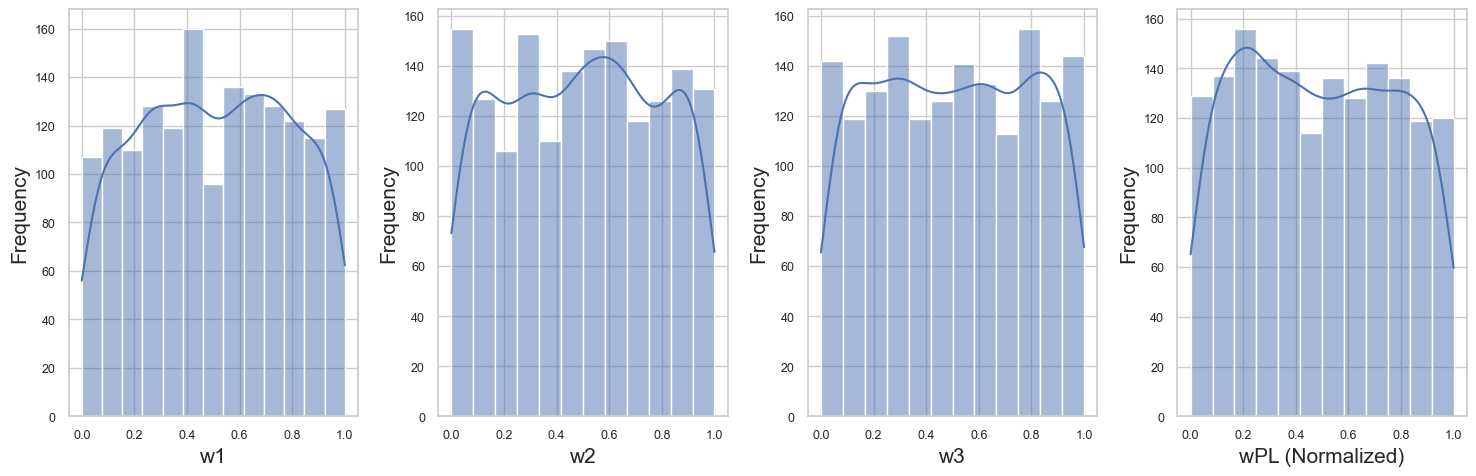

/var/folders/cl/wxhg84_d06q47nm4f6nr73500000gn/T/ipykernel_68665/2923007993.py:67: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45)
/var/folders/cl/wxhg84_d06q47nm4f6nr73500000gn/T/ipykernel_68665/2923007993.py:67: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45)
/var/folders/cl/wxhg84_d06q47nm4f6nr73500000gn/T/ipykernel_68665/2923007993.py:67: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45)
/var/folders/cl/wxhg84_d06q47nm4f6nr73500000gn/T/ipykernel_68665/2923007993.py:67: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a Fi

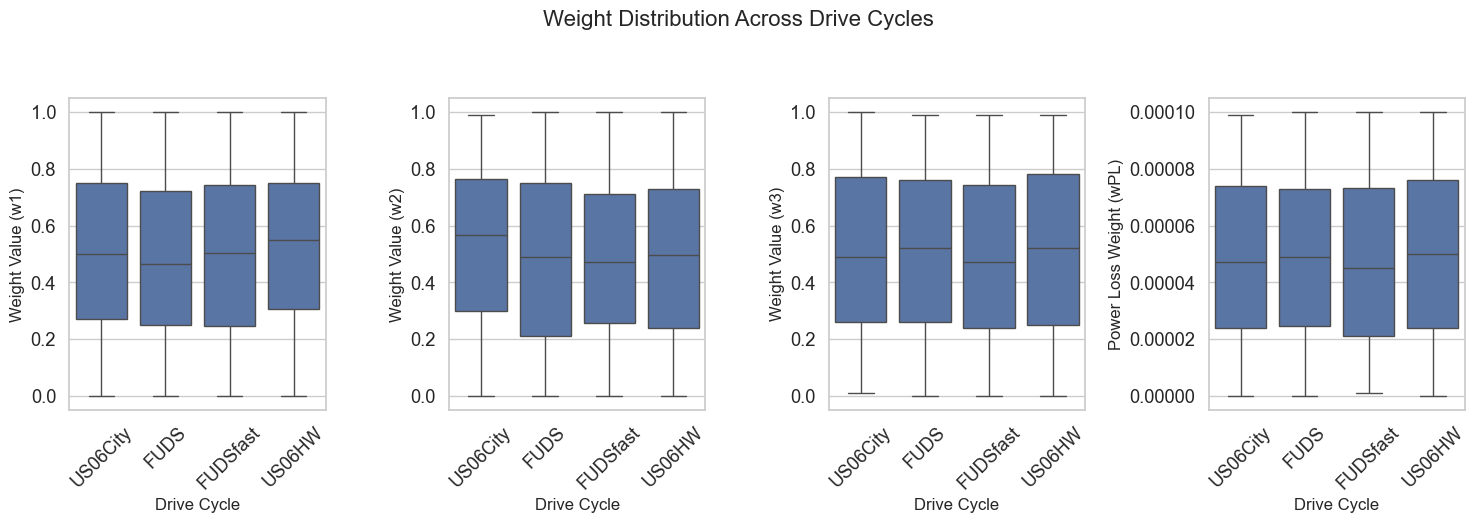

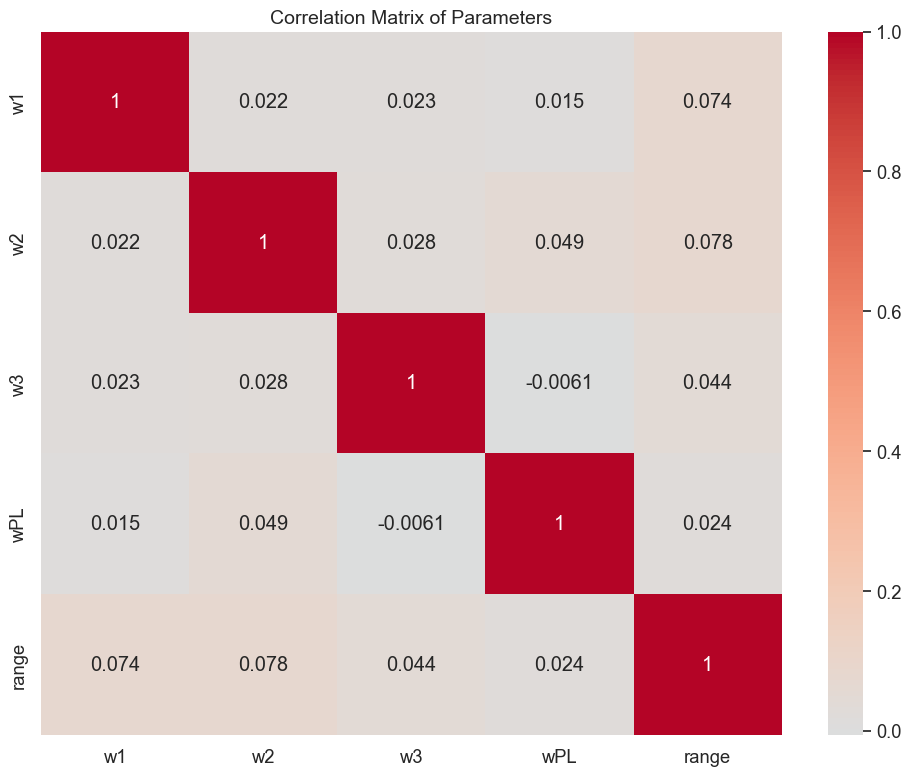

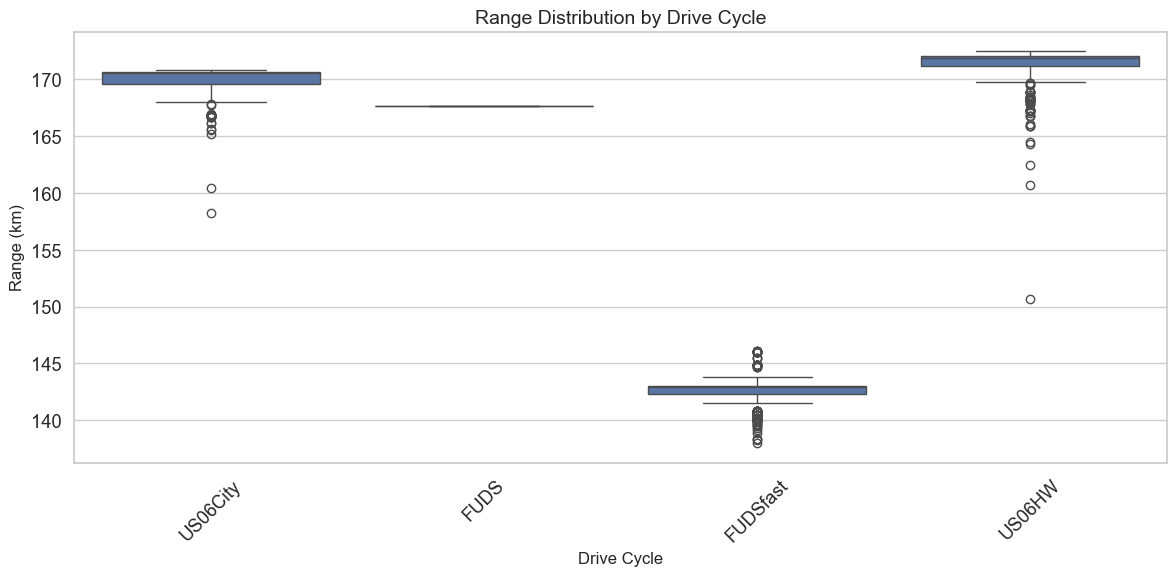

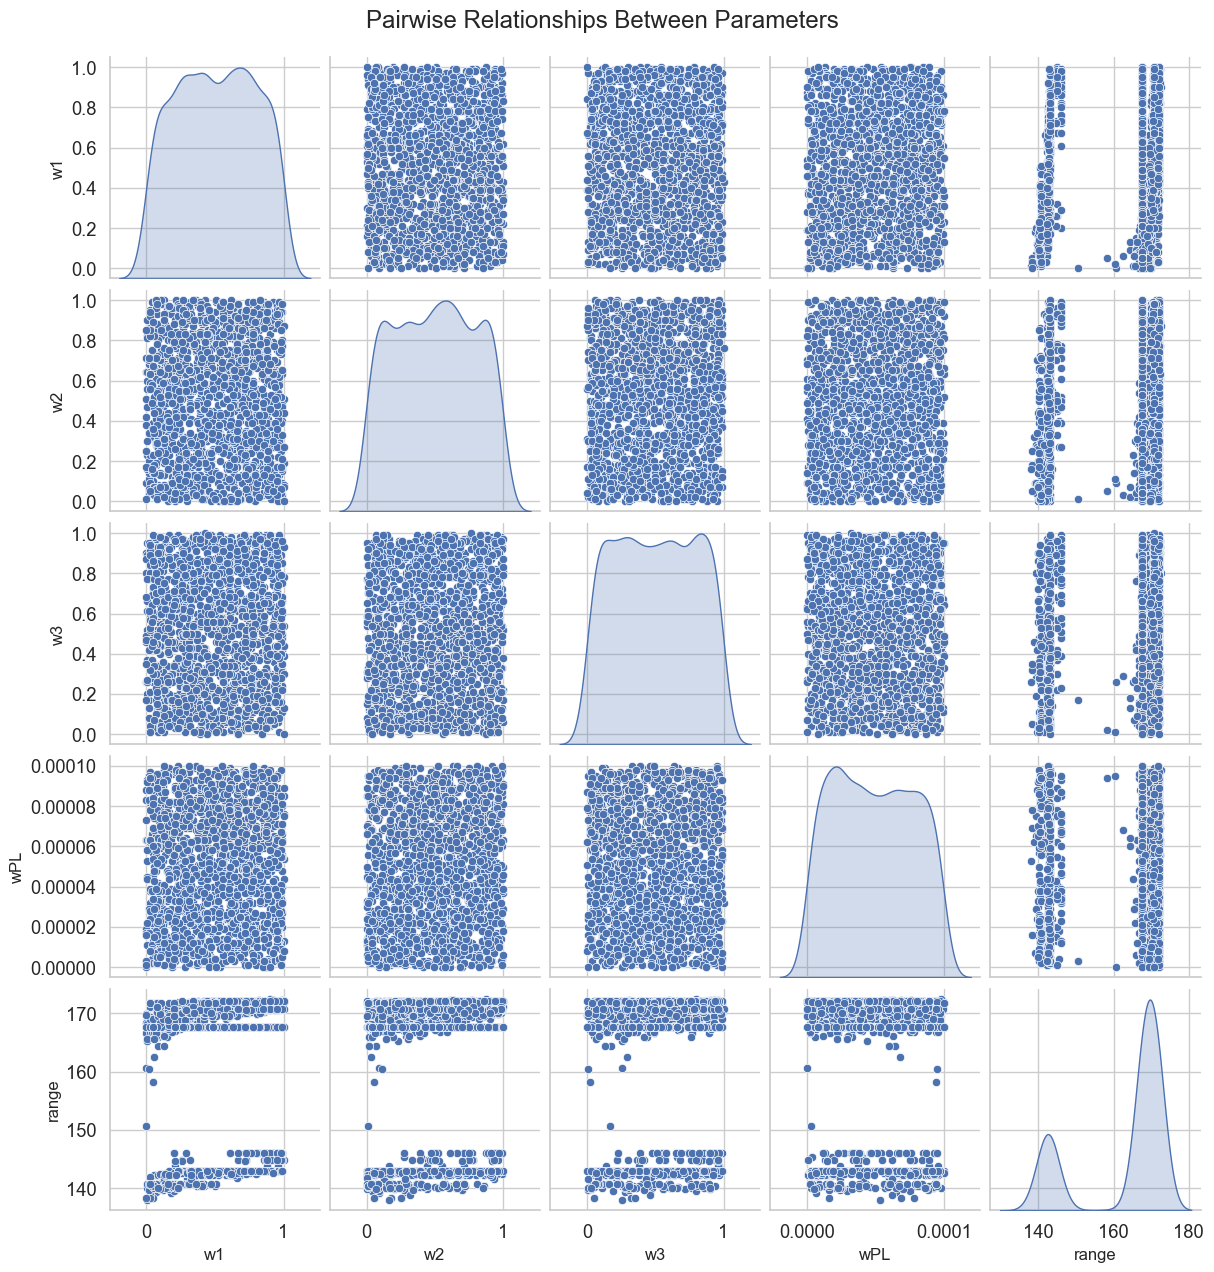

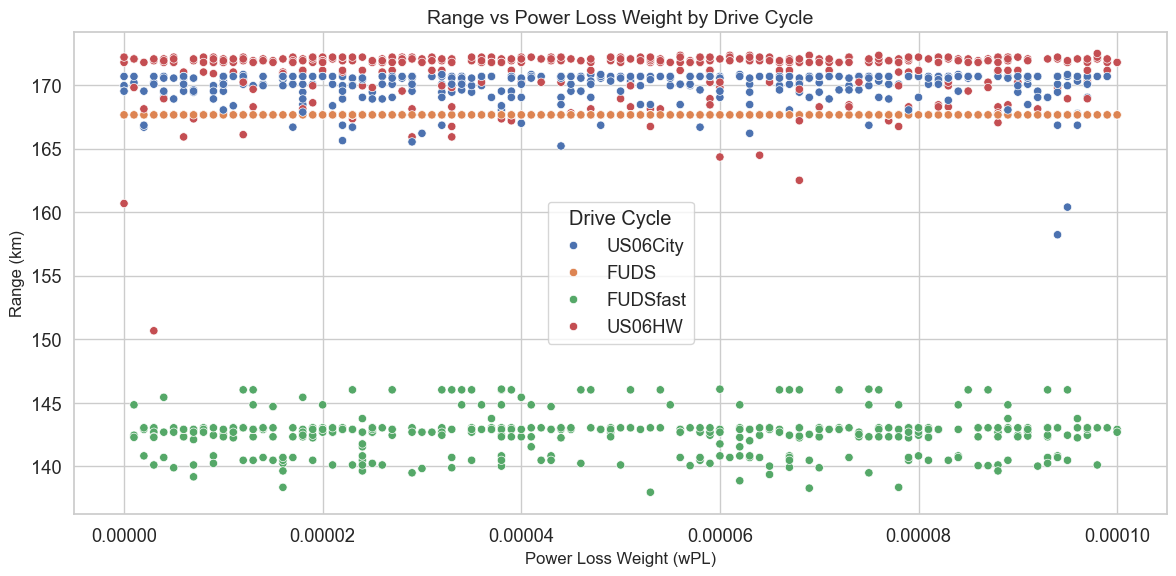

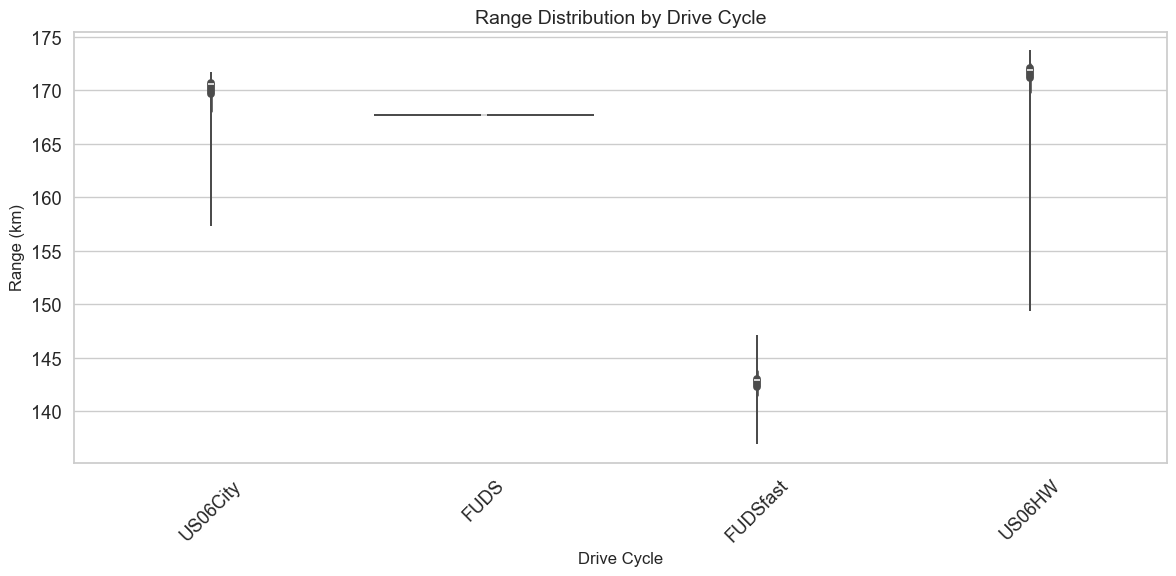

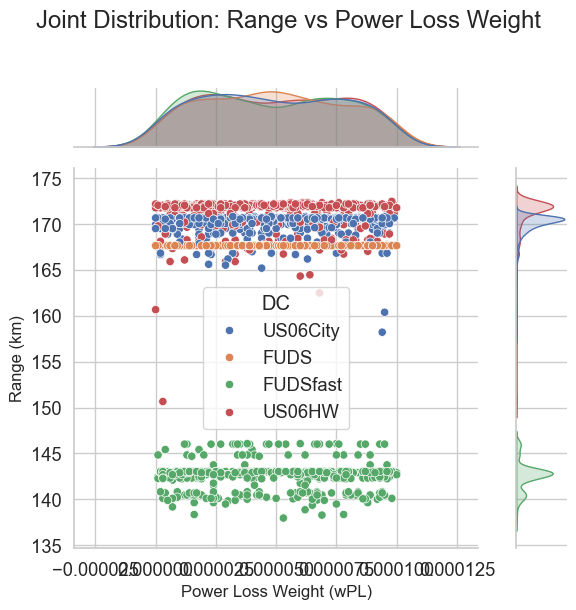

In [13]:

# Distribution plots for w1, w2, w3, WPL
fig, axes = plt.subplots(1, 4, figsize=(15, 5))
sns.histplot(data=dataset, x='w1', kde=True, ax=axes[0])
sns.histplot(data=dataset, x='w2', kde=True, ax=axes[1])
sns.histplot(data=dataset, x='w3', kde=True, ax=axes[2])


# scaling wPL to 0-1 range for better visualization
wpl_min = dataset['wPL'].min()
wpl_max = dataset['wPL'].max()
wpl_dataset = (dataset['wPL'] - wpl_min) / (wpl_max - wpl_min)

sns.histplot(data=wpl_dataset, kde=True, ax=axes[3])

# Add labels for distribution plots
# axes[0].set_title('Weight 1 Distribution', fontsize=12)
axes[0].set_xlabel('w1', fontsize=15)
axes[0].set_ylabel('Frequency', fontsize=15)

# axes[1].set_title('Weight 2 Distribution', fontsize=12)
axes[1].set_xlabel('w2', fontsize=15)
axes[1].set_ylabel('Frequency', fontsize=15)

# axes[2].set_title('Weight 3 Distribution', fontsize=12)
axes[2].set_xlabel('w3', fontsize=15)
axes[2].set_ylabel('Frequency', fontsize=15)

# axes[3].set_title('Power Loss Weight Distribution', fontsize=12)
axes[3].set_xlabel('wPL (Normalized)', fontsize=15)
axes[3].set_ylabel('Frequency', fontsize=15)

# Increase tick label font size
for ax in axes:
    ax.tick_params(axis='both', labelsize=9)


# fig.suptitle('Distribution of Weights', fontsize=16, y=1.05)
plt.tight_layout()
plt.show()

# Box plots for weights by driving cycle
fig, axes = plt.subplots(1, 4, figsize=(15, 5))
sns.boxplot(data=dataset, x='DC', y='w1', ax=axes[0])
sns.boxplot(data=dataset, x='DC', y='w2', ax=axes[1])
sns.boxplot(data=dataset, x='DC', y='w3', ax=axes[2])
sns.boxplot(data=dataset, x='DC', y='wPL', ax=axes[3])

# Add labels for box plots
# axes[0].set_title('Weight 1 by Drive Cycle')
axes[0].set_xlabel('Drive Cycle')
axes[0].set_ylabel('Weight Value (w1)')

# axes[1].set_title('Weight 2 by Drive Cycle')
axes[1].set_xlabel('Drive Cycle')
axes[1].set_ylabel('Weight Value (w2)')

# axes[2].set_title('Weight 3 by Drive Cycle')
axes[2].set_xlabel('Drive Cycle')
axes[2].set_ylabel('Weight Value (w3)')

# axes[3].set_title('Power Loss Weight by Drive Cycle')
axes[3].set_xlabel('Drive Cycle')
axes[3].set_ylabel('Power Loss Weight (wPL)')

fig.suptitle('Weight Distribution Across Drive Cycles', fontsize=16, y=1.05)
for ax in axes:
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45)
plt.tight_layout()
plt.show()

# Correlation analysis
numeric_cols = ['w1', 'w2', 'w3', 'wPL', 'range']
correlation_matrix = dataset[numeric_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0)
plt.title('Correlation Matrix of Parameters')
plt.tight_layout()
plt.show()

# Range distribution by driving cycle
plt.figure(figsize=(12, 6))
sns.boxplot(data=dataset, x='DC', y='range')
plt.title('Range Distribution by Drive Cycle')
plt.xlabel('Drive Cycle')
plt.ylabel('Range (km)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Scatter plot matrix
g = sns.pairplot(dataset[numeric_cols], diag_kind='kde')
g.fig.suptitle('Pairwise Relationships Between Parameters', y=1.02)
plt.show()

# Save figures
plt.figure(figsize=(12, 6))
sns.scatterplot(data=dataset, x='wPL', y='range', hue='DC')
plt.title('Range vs Power Loss Weight by Drive Cycle')
plt.xlabel('Power Loss Weight (wPL)')
plt.ylabel('Range (km)')
plt.legend(title='Drive Cycle')
plt.tight_layout()
plt.savefig('range_vs_wPL.png', dpi=300, bbox_inches='tight')
plt.show()

# Violin plot
plt.figure(figsize=(12, 6))
sns.violinplot(data=dataset, x='DC', y='range')
plt.title('Range Distribution by Drive Cycle')
plt.xlabel('Drive Cycle')
plt.ylabel('Range (km)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Joint plot
g = sns.jointplot(
    data=dataset,
    x='wPL',
    y='range',
    hue='DC',
    kind='scatter'
)
g.fig.suptitle('Joint Distribution: Range vs Power Loss Weight', y=1.02)
g.ax_joint.set_xlabel('Power Loss Weight (wPL)')
g.ax_joint.set_ylabel('Range (km)')
plt.tight_layout()
plt.show()